# Nightside temperatures of the most hyper-illuminated planets

With an extended star the penumbra reaches past 90°, so a bare rock without heat transport gets a warm ring around a cold nightside. This notebook computes that nightside signal and what a point-source fit with Kreidberg & Loeb (2016) redistribution reports for it. Four temperatures are kept apart:

- $T_{\rm b,night}$: in-band brightness temperature of the thermal signal at mid-transit, **edge-on** ($i = 90°$), i.e. the night hemisphere alone. Section 3 also shows it at the planet's inclination, where it includes the dayside seen past the pole.
- $T_{\rm b,day}$: in-band brightness temperature of the thermal occultation depth.
- $T_{\rm night}^{\rm KL}$: the uniform nightside temperature implied by the $(A_B, F)$ of a point-source fit with redistribution to the noiseless extended-source curve. That curve has $F = 0$, so any fitted $F$ is spurious.
- $A_T = 1 - T_{\rm b,night}/T_{\rm b,day}$: the day-night contrast (Sadh & Gavassino 2026, eq. 14).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import replace
from astropy import constants as const
from hyperphase.irradiance import hemisphere_temperatures
from hyperphase.planet import PlanetParams
from hyperphase.defaults import (A_B_FIT_BOUNDS, DEFAULT_A, DEFAULT_A_B, DEFAULT_N_BINS, DEFAULT_N_LA, DEFAULT_N_LO, DEFAULT_N_ORBITS, DEFAULT_U,
                                 DEFAULT_U_BOL, F_BOUNDS)
from hyperphase.model import ConstantBandAlbedo, FittingConfig
from hyperphase.phasecurve import nightside_flux
from hyperphase.stellar import T_bright
from hyperphase.bias.detectors import detectors, instrument_cfg, instrument_key
from hyperphase.bias.fisher import model_depth
from hyperphase.bias.tables import display_formatted
from hyperphase.parallel import pmap
from hyperphase.plotting.bias import planet_label, plot_nightside_spectra, plot_nightside_survey, plot_sg_comparison
from hyperphase.plotting.style import instrument_label, set_plot_style
from hyperphase.bias.tables import _instrument_false_F_row   # one planet x instrument row of instrument_false_F (a private helper)
from hyperphase.bands import filter_lambda, filter_loc, JWST_BANDS
from hyperphase.noise import noise_levels
from hyperphase.paper import JWST_RETRIEVALS, PAPER_PLANETS
from hyperphase.targets import AU_IN_R_SUN, hi_planets_by_name

In [2]:
u, u_bol = DEFAULT_U, DEFAULT_U_BOL          # transit and irradiance limb darkening
A_B_true = DEFAULT_A_B                  # Bond albedo of the truth
A_model = ConstantBandAlbedo(DEFAULT_A)  # band albedo of the reflected light, independent of A_B
A = A_model(A_B_true)
n_bins, n_orbits = DEFAULT_N_BINS, DEFAULT_N_ORBITS
bounds, F_bounds = A_B_FIT_BOUNDS, F_BOUNDS   # A_B may fit below the physical floor 0
kw = dict(n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA)   # insolation grid of every evaluation
N_LAYERS_NIGHT = 200                    # SPIDERMAN layers of the single-epoch quantities: 400 changes them by 0.1 % (TOI-2431 b, LRS); the light-curve defaults are 40 / 80
Z_F = 2.                                # significance at which a spurious F counts as detected

planets = hi_planets_by_name(PAPER_PLANETS)
SURVEY_BAND = "MIRI/LRS"                # part A: all planets in this band
FOCUS = ["TOI-2431 b", "K2-141 b"]      # part B: these planets in every band
BANDS, FIT_BANDS = JWST_BANDS, JWST_RETRIEVALS   # FIT_BANDS adds the joint NRS1 + NRS2 fit (shared A_B, F; a baseline per detector)
NOISE_LABEL = rf"$\sigma_{{\rm amp}}$ ({n_orbits} orbits)"   # noise of a fitted phase-curve amplitude, FittingConfig.sigma_amp

cfg = FittingConfig(planet=planets[FOCUS[0]], filter_path=None, l1=np.nan, l2=np.nan, A_=A_model, sigma_1min=100., n_orbits=n_orbits, n_bins=n_bins, reflected=True, u_bol=u_bol, u=u)
set_plot_style()

display_formatted(pd.DataFrame([dict(name=pl.name, a_rs=pl.R / pl.r2, rp_rs=pl.r1 / pl.r2, incl=pl.incl, T_eff=pl.T2_eff, P_h=24. * pl.period,
                                     term=pl.terminator_nightside("deg"), lit=100. * pl.fraction_illuminated()) for pl in planets.values()]),
                  {"a_rs": ("a/R*", "{:.2f}"), "rp_rs": ("Rp/R*", "{:.4f}"), "incl": ("i [deg]", "{:.1f}"), "T_eff": ("T_eff [K]", "{:.0f}"), "P_h": ("P [h]", "{:.2f}"),
                   "term": ("terminator [deg]", "{:.1f}"), "lit": ("lit fraction [%]", "{:.1f}")}, transpose=True)

,TOI-2431 b,TOI-2260 b,K2-141 b,K2-131 b,TOI-561 b,Kepler-78 b,TOI-1444 b,TOI-1798.02,HD 80653 b,55 Cnc e
a/R*,2.08,2.22,2.29,2.66,2.68,2.70,2.73,2.90,2.97,3.52
Rp/R*,0.0213,0.0158,0.0204,0.0204,0.0152,0.0147,0.0141,0.0162,0.0124,0.0182
i [deg],74.0,69.7,86.3,85.0,87.0,75.2,82.0,83.7,81.7,83.6
T_eff [K],4109,5534,4599,5120,5372,5058,5430,5106,5959,5172
P [h],5.38,8.46,6.73,8.86,10.72,8.52,11.29,10.51,17.27,17.68
terminator [deg],118.1,116.3,115.3,111.6,111.5,111.4,111.2,109.8,109.4,106.2
lit fraction [%],73.5,72.2,71.4,68.4,68.4,68.2,68.1,66.9,66.6,63.9


## 1. Nightside signal and point-source fits

Two row functions, run in parallel over every planet in `SURVEY_BAND` and every band of the `FOCUS` planets (a few minutes). `band_row` gives the thermal nightside signal at mid-transit (extended source edge-on and at the planet's inclination, point source at its inclination), both occultation depths and their brightness temperatures. `fit_row` fits the extended-source truth with the point-source model without and with redistribution, giving $T_{\rm night}^{\rm KL} = [(1-A_{B,\rm fit})\,F_{\rm fit}\,S/2\sigma]^{1/4}$. The noise enters only $\sigma_{\rm amp} = \sigma_{\rm 1\,min}\sqrt{2/t_{\rm obs}}$, the noise of a fitted sinusoid amplitude (Montgomery & O'Donoghue 1999), and the significance $z_F$ of the spurious $F$. Reflected light (below 0.1 ppm at transit) is left out.

In [3]:
def band_row(pl, instrument, A_B_=A_B_true, A_band=A, u_bol_=u_bol):
    '''Thermal single-epoch quantities of one planet in one band: nightside signal at mid-transit [ppm] (hi = extended, ps = point source; _90 = edge-on), occultation depth [ppm], brightness temperatures [K].'''
    lam, fp = filter_lambda(instrument, pl), filter_loc(instrument)   # the planet's own part of the band where its host saturates the rest (PARTIAL_BANDS), as c integrates
    pl_90 = replace(pl, incl=90.)
    nf = lambda p, model, unit="flux": nightside_flux(p, lam, model, unit=unit, filter_path=fp, u_bol=u_bol_, A_B=A_B_, A=A_band, N_LAYERS=N_LAYERS_NIGHT, **kw)
    c = replace(instrument_cfg(cfg, instrument), planet=pl, reflected=False, u_bol=u_bol_)   # thermal-only depth: T_bright inverts thermal emission
    depth_hi, depth_ps = (model_depth(c, m, A_B_, n_layers=N_LAYERS_NIGHT, **kw) for m in ("hyperillum", "naive"))
    return dict(name=pl.name, instrument=instrument, a_rs=pl.R / pl.r2,
                night_hi=nf(pl, "hyperillum")[0], night_ps=nf(pl, "naive")[0], night_hi_90=nf(pl_90, "hyperillum")[0],
                T_night=nf(pl, "hyperillum", "temperature"), T_night_90=nf(pl_90, "hyperillum", "temperature"),
                T_day=T_bright(depth_hi, pl, lam, filter_path=fp), T_day_ps=T_bright(depth_ps, pl, lam, filter_path=fp))


SIGMA_REF = 100.   # [ppm/min] stand-in for a band without a noise level: a single-band fit does not depend on it, its z_F is dropped

def fit_row(name, instrument):
    dets = detectors(instrument)
    lv = {d: noise[name].get(d, np.nan) for d in dets}
    has_noise = all(np.isfinite(s) for s in lv.values())
    if len(dets) > 1 and not has_noise: return None
    row = _instrument_false_F_row(cfg, A_B_true, planets[name], instrument_key(instrument), {d: s if has_noise else SIGMA_REF for d, s in lv.items()}, bounds, F_bounds, kw)
    return dict(name=name, has_noise=has_noise, **row)


night_pairs = [(nm, SURVEY_BAND) for nm in planets] + [(nm, b) for nm in FOCUS for b in BANDS if b != SURVEY_BAND]
fit_pairs = [(nm, SURVEY_BAND) for nm in planets] + [(nm, b) for nm in FOCUS for b in FIT_BANDS if b != SURVEY_BAND]
noise = {nm: noise_levels(planets[nm], BANDS) for nm in planets}   # {planet: {band: sigma_1min}}; a band without a level is absent

night = pd.DataFrame(pmap(band_row, [(planets[nm], b) for nm, b in night_pairs]))
night["sigma_amp"] = [replace(cfg, planet=planets[nm], sigma_1min=noise[nm].get(b, np.nan)).sigma_amp for nm, b in night_pairs]   # NaN without a noise level
night["A_T_90"] = 1. - night["T_night_90"] / night["T_day"]

fits = pd.DataFrame([r for r in pmap(fit_row, fit_pairs) if r is not None])
fits["z_F"] = np.sqrt(fits["dchi2_F"]).where(fits["has_noise"])
fits["T_night_fit"] = fits["T_night_fit"].where(np.isfinite(fits["F_fit"]))   # railed: F undefined, so is the nightside it implies
fits = fits[["name", "instrument", "A_B_fit", "F_fit", "T_night_fit", "z_F", "railed"]].merge(night[["name", "instrument", "T_night_90"]], on=["name", "instrument"], how="left")
fits["dT_night_fit"] = fits["T_night_fit"] - fits["T_night_90"]

## 2. All paper planets in MIRI/LRS

The band of TOI-2431 b's scheduled phase curve, with a noise level for every planet (55 Cnc e only over 6.7–10.5 µm, `PARTIAL_BANDS`). Top: the nightside signal against $\sigma_{\rm amp}$; bottom: how far $T_{\rm night}^{\rm KL}$ lies above the true nightside, and where the spurious $F$ would be detected.

In [4]:
survey = night[night["instrument"] == SURVEY_BAND].merge(fits.drop(columns="T_night_90"), on=["name", "instrument"])
display_formatted(survey, {"a_rs": ("a/R*", "{:.2f}"), "night_hi_90": ("night signal [ppm]", "{:.2f}"), "sigma_amp": ("sigma_amp [ppm]", "{:.2f}"),
                           "T_night_90": ("T_b,night [K]", "{:.0f}"), "T_day": ("T_b,day [K]", "{:.0f}"), "A_T_90": ("A_T", "{:.3f}"),
                           "A_B_fit": ("A_B fit", "{:.3f}"), "F_fit": ("F fit", "{:.4f}"), "T_night_fit": ("T_night^KL [K]", "{:.0f}"),
                           "dT_night_fit": ("T_night^KL - T_b,night [K]", "{:+.0f}"), "z_F": ("z_F", "{:.2f}")})

,a/R*,night signal [ppm],sigma_amp [ppm],"T_b,night [K]","T_b,day [K]",A_T,A_B fit,F fit,T_night^KL [K],"T_night^KL - T_b,night [K]",z_F
TOI-2431 b,2.08,6.32,2.21,506,2375,0.787,0.031,0.0058,656,+150,2.83
TOI-2260 b,2.22,3.85,3.21,569,3062,0.814,0.040,0.0037,762,+193,1.07
K2-141 b,2.29,4.55,3.12,491,2563,0.809,0.044,0.0040,634,+143,1.50
K2-131 b,2.66,2.92,7.69,451,2644,0.829,0.091,0.0027,589,+138,0.41
TOI-561 b,2.68,1.69,2.48,462,2764,0.833,0.087,0.0025,604,+142,0.73
Kepler-78 b,2.70,1.44,5.65,444,2561,0.826,0.091,0.0033,604,+160,0.27
TOI-1444 b,2.73,1.38,3.54,458,2760,0.834,0.099,0.0024,599,+141,0.42
TOI-1798.02,2.90,1.32,4.06,417,2519,0.834,0.113,0.0025,549,+131,0.37
HD 80653 b,2.97,0.87,1.63,446,2900,0.846,0.102,0.0020,601,+155,0.60
55 Cnc e,3.52,0.95,0.49,339,2233,0.848,0.125,0.0019,466,+127,2.48


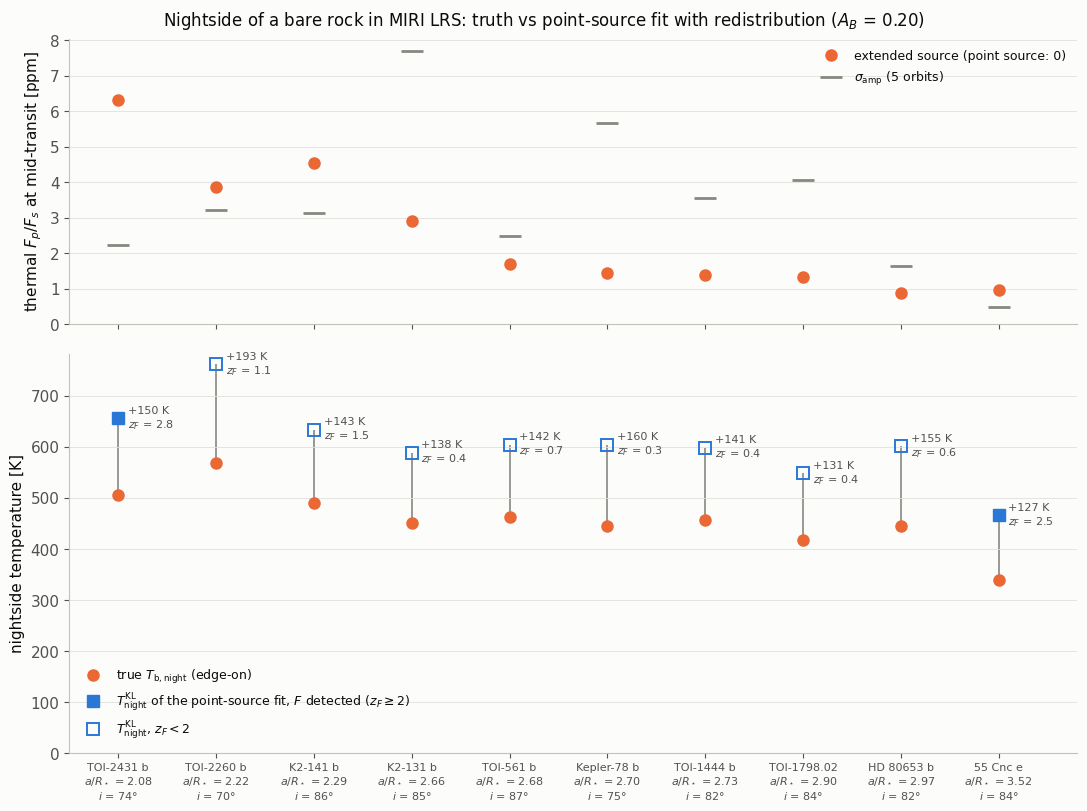

In [5]:
fig = plot_nightside_survey(survey, planets, Z_F, NOISE_LABEL)
fig.suptitle(rf"Nightside of a bare rock in {instrument_label(SURVEY_BAND, oneline=True)}: truth vs point-source fit with redistribution ($A_B$ = {A_B_true:.2f})", fontsize=12, y=1.01)
plt.show()

## 3. TOI-2431 b and K2-141 b in every band

The two retrieval planets in every band: TOI-2431 b, the most hyper-illuminated ($a/R_\star$ = 2.08), at $i = 74°$, and the almost edge-on K2-141 b. The figure shows how $T_{\rm b,night}$ falls with wavelength, which a uniform nightside cannot reproduce, and how much of the signal at the planet's inclination is dayside seen past the pole (`dayside leak / signal`).

In [6]:
spec = night[night["name"].isin(FOCUS)].merge(fits[fits["name"].isin(FOCUS)].drop(columns="T_night_90"), on=["name", "instrument"], how="outer")
spec["instrument"] = pd.Categorical(spec["instrument"], categories=[instrument_key(b) for b in FIT_BANDS], ordered=True)
spec = spec.sort_values(["name", "instrument"])
spec["band"] = [instrument_label(b, oneline=True) for b in spec["instrument"]]
spec["leak"] = spec["night_ps"] / spec["night_hi"]
for nm in FOCUS:
    print(planet_label(planets[nm], newline=False))
    display_formatted(spec[spec["name"] == nm], {"night_hi_90": ("night signal, edge-on [ppm]", "{:.2f}"), "night_hi": ("night signal, planet's i [ppm]", "{:.2f}"),
                                                 "leak": ("dayside leak / signal", "{:.2f}"), "sigma_amp": ("sigma_amp [ppm]", "{:.2f}"),
                                                 "T_night_90": ("T_b,night edge-on [K]", "{:.0f}"), "T_night": ("T_b,night planet's i [K]", "{:.0f}"), "T_day": ("T_b,day [K]", "{:.0f}"),
                                                 "A_B_fit": ("A_B fit", "{:.3f}"), "F_fit": ("F fit", "{:.4f}"), "T_night_fit": ("T_night^KL [K]", "{:.0f}"), "dT_night_fit": ("T_night^KL - T_b,night [K]", "{:+.0f}"), "z_F": ("z_F", "{:.2f}")}, index="band")

TOI-2431 b, $a/R_\star$ = 2.08, $i$ = 74°


,"night signal, edge-on [ppm]","night signal, planet's i [ppm]",dayside leak / signal,sigma_amp [ppm],"T_b,night edge-on [K]","T_b,night planet's i [K]","T_b,day [K]",A_B fit,F fit,T_night^KL [K],"T_night^KL - T_b,night [K]",z_F
NIRSpec G395H NRS1,1.50,3.28,0.21,1.38,693,793,2384,0.107,0.0194,870,+176,1.67
NIRSpec G395H NRS2,2.91,5.56,0.19,1.74,625,712,2379,0.083,0.0128,788,+164,2.08
NIRSpec G395H NRS1 + NRS2,-,-,-,-,-,-,-,0.106,0.0140,802,-,2.47
MIRI LRS,6.32,10.33,0.17,2.21,506,581,2375,0.031,0.0058,656,+150,2.83
MIRI F1280W,10.87,16.16,0.15,8.70,407,469,2373,-0.034,0.0025,541,+134,1.08
MIRI F1500W,12.05,17.60,0.14,9.29,381,441,2372,-0.049,0.0020,513,+132,1.10
MIRI F1800W,13.28,19.07,0.14,13.94,355,413,2372,-0.065,0.0016,485,+130,0.78


K2-141 b, $a/R_\star$ = 2.29, $i$ = 86°


,"night signal, edge-on [ppm]","night signal, planet's i [ppm]",dayside leak / signal,sigma_amp [ppm],"T_b,night edge-on [K]","T_b,night planet's i [K]","T_b,day [K]",A_B fit,F fit,T_night^KL [K],"T_night^KL - T_b,night [K]",z_F
NIRSpec G395H NRS1,1.09,1.17,0.00,1.66,686,694,2569,0.117,0.0145,859,+172,1.03
NIRSpec G395H NRS2,2.13,2.26,0.00,2.14,614,621,2566,0.094,0.0092,773,+158,1.27
NIRSpec G395H NRS1 + NRS2,-,-,-,-,-,-,-,0.116,0.0101,785,-,1.49
MIRI LRS,4.55,4.74,0.00,3.12,491,496,2563,0.044,0.0040,634,+143,1.50
MIRI F1280W,7.78,8.04,0.00,-,389,393,2562,-0.017,0.0016,514,+126,-
MIRI F1500W,8.62,8.89,0.00,-,362,366,2562,-0.031,0.0013,485,+123,-
MIRI F1800W,9.50,9.78,0.00,-,335,339,2562,-0.046,0.0010,456,+121,-


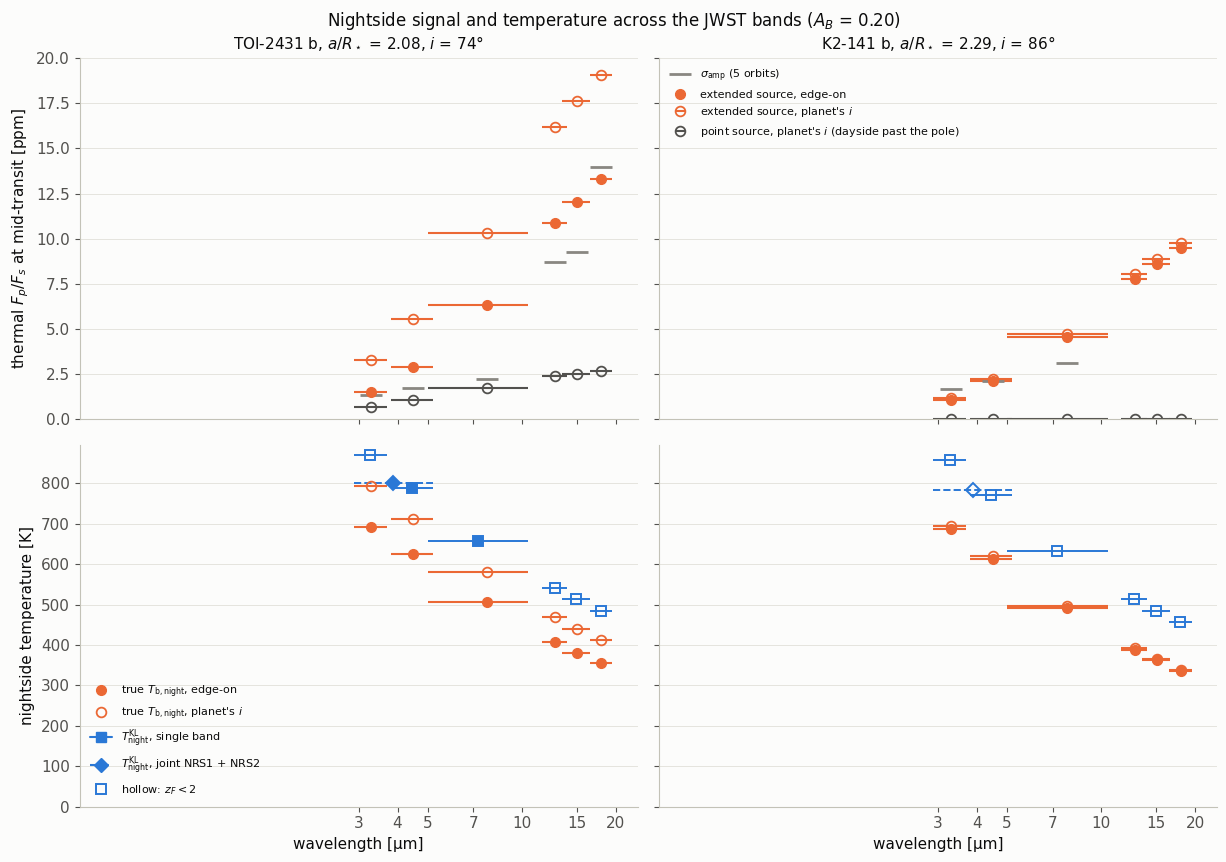

In [7]:
fig = plot_nightside_spectra(night, fits, planets, FOCUS, Z_F, NOISE_LABEL)
fig.suptitle(rf"Nightside signal and temperature across the JWST bands ($A_B$ = {A_B_true:.2f})", fontsize=12, y=1.01)
plt.show()

## 4. Comparison with Sadh & Gavassino (2026), Table 2

Their Table 2 gives day- and nightside temperatures of five USP planets for a bare rock with $A_B = 0$, from $T = (\langle I\rangle/\sigma)^{1/4}$ with the insolation averaged **uniformly** over the angle $\gamma_1$ from the substellar point (their eqs. 15–17), which is neither an area mean nor an observable. `hemisphere_temperatures` evaluates three weights on our insolation; for a point source $T = T_0 f^{1/4}$ with $T_0 = T_{\rm eff}\sqrt{R_\star/a}$:

| hemisphere quantity | weight in $\gamma_1$ (dayside) | point source $f$ |
|---|---|---|
| S&G eqs. 15–17 | ${\rm d}\gamma_1/(\pi/2)$ | $2/\pi = 0.637$ |
| area mean of the flux | $\sin\gamma_1\,{\rm d}\gamma_1$ | $1/2$ |
| bolometric disk-integrated $T_b$ along the star-planet axis (Teske et al. 2025, $T_{d,\max}$) | $2\,\lvert\cos\gamma_1\rvert\sin\gamma_1\,{\rm d}\gamma_1$ | $2/3$ |

On the nightside the emission sits just beyond 90°, where $\sin\gamma_1 \approx 1 > 2/\pi$, so the uniform weight under-counts it. Settings are S&G's ($A_B = A = 0$, $u_{\rm bol} = 0.6$; K2-141 b and 55 Cnc e from their Table 1, the other three reconstructed from the exoplanet.eu catalogs shipped with InstellCa). The table gives the reproduction of their columns (`repro_*`) and the nightside and $A_T$ under each definition; the LRS column is the observable.

In [8]:
R_JUP_RSUN, R_EARTH_RSUN = float(const.R_jup / const.R_sun), float(const.R_earth / const.R_sun)
U_BOL_SG = 0.6   # S&G's limb darkening (InstellCa default), not the baseline u_bol


def sg_planet(name, a_AU, r2_rsun, r1_rsun, T2_eff, period, incl):
    '''PlanetParams in solar radii for the S&G comparison (no T14: no PandExo). log g and [Fe/H] (stellar SED only) from the archive / CUSTOM, defaults where the planet is not there.'''
    try: host = hi_planets_by_name(name); logg, feh = host.logg, host.feh
    except KeyError: logg, feh = 4.5, 0.0
    return PlanetParams(name=name, period=period, incl=incl, ecc=0., w=90., r1=r1_rsun, r2=r2_rsun, R=a_AU * AU_IN_R_SUN, T2_eff=T2_eff, a_AU=a_AU, T14=np.nan, logg=logg, feh=feh)


SG_PLANETS = {
    "K2-141 b":    sg_planet("K2-141 b",    0.0075,  0.68,  1.50 * R_EARTH_RSUN,  4599., 0.280324, 86.3),   # a, R*, Rp: S&G Table 1; T_eff, P, i: exoplanet.eu_catalog_new.csv
    "55 Cnc e":    sg_planet("55 Cnc e",    0.0154,  0.98,  1.88 * R_EARTH_RSUN,  5196., 0.736548, 90.),    # a, R*, Rp: S&G Table 1; T_eff, P: exoplanet.eu_catalog.csv; i = 90.36 there
    "TOI-561 b":   sg_planet("TOI-561 b",   0.01064, 0.832, 0.12463 * R_JUP_RSUN, 5326., 0.446570, 87.0),   # exoplanet.eu_catalog_new.csv (not in S&G Table 1)
    "TOI-431 b":   sg_planet("TOI-431 b",   0.01130, 0.731, 0.11420 * R_JUP_RSUN, 4850., 0.490047, 84.3),   # exoplanet.eu_catalog_new.csv
    "Kepler-10 b": sg_planet("Kepler-10 b", 0.01685, 1.060, 0.13110 * R_JUP_RSUN, 5708., 0.837491, 84.8),   # exoplanet.eu_catalog_new.csv
}
SG_TABLE2 = {"K2-141 b": (2686., 854.), "55 Cnc e": (2560., 691.), "TOI-561 b": (2887., 851.), "TOI-431 b": (2415., 650.), "Kepler-10 b": (2825., 763.)}   # (day-side, night-side) [K]


rows = []
for nm, pl in SG_PLANETS.items():
    T0 = pl.T2_eff * np.sqrt(pl.r2 / pl.R)
    ps = hemisphere_temperatures(pl, "naive", u_bol=U_BOL_SG, A_B=0.)   # analytic check of the quadrature: T0 f^(1/4) with f = 2/pi, 1/2, 2/3
    assert np.allclose([ps["uniform_day"], ps["area_day"], ps["disk_day"]], T0 * np.array([2. / np.pi, 0.5, 2. / 3.]) ** 0.25, rtol=1e-8), nm
    rows.append(dict(name=nm, a_rs=pl.R / pl.r2, pub_day=SG_TABLE2[nm][0], pub_night=SG_TABLE2[nm][1], teske=T0 * (2. / 3.) ** 0.25, **hemisphere_temperatures(pl, u_bol=U_BOL_SG, A_B=0.)))
sg = pd.DataFrame(rows)

sg_band = pd.DataFrame(pmap(band_row, [(pl, SURVEY_BAND, 0., 0., U_BOL_SG) for pl in SG_PLANETS.values()]))   # the observable: in-band T_b, A_B = 0, no reflected light
sg["band_day"], sg["band_night"] = sg_band["T_day"], sg_band["T_night_90"]
sg["repro_day"], sg["repro_night"] = sg["uniform_day"] / sg["pub_day"] - 1., sg["uniform_night"] / sg["pub_night"] - 1.
for key in ("pub", "uniform", "area", "disk", "band"):
    sg[f"A_T_{key}"] = 1. - sg[f"{key}_night"] / sg[f"{key}_day"]

lab = instrument_label(SURVEY_BAND, oneline=True)
display_formatted(sg, {"pub_day": ("day: S&G Table 2 [K]", "{:.0f}"), "uniform_day": ("day: S&G recipe [K]", "{:.0f}"), "repro_day": ("day: recipe / Table 2 - 1", "{:+.2%}"),
                       "area_day": ("day: area mean [K]", "{:.0f}"), "disk_day": ("day: bolometric disk [K]", "{:.0f}"), "teske": ("day: Teske T_d,max [K]", "{:.0f}"), "band_day": (f"day: {lab} T_b [K]", "{:.0f}"),
                       "pub_night": ("night: S&G Table 2 [K]", "{:.0f}"), "uniform_night": ("night: S&G recipe [K]", "{:.0f}"), "repro_night": ("night: recipe / Table 2 - 1", "{:+.2%}"),
                       "area_night": ("night: area mean [K]", "{:.0f}"), "disk_night": ("night: bolometric disk [K]", "{:.0f}"), "band_night": (f"night: {lab} T_b [K]", "{:.0f}"),
                       "A_T_pub": ("A_T: S&G", "{:.3f}"), "A_T_area": ("A_T: area mean", "{:.3f}"), "A_T_disk": ("A_T: bolometric disk", "{:.3f}"), "A_T_band": (f"A_T: {lab}", "{:.3f}")}, transpose=True)

,K2-141 b,55 Cnc e,TOI-561 b,TOI-431 b,Kepler-10 b
day: S&G Table 2 [K],2686,2560,2887,2415,2825
day: S&G recipe [K],2680,2531,2878,2382,2763
day: recipe / Table 2 - 1,-0.23%,-1.14%,-0.31%,-1.38%,-2.18%
day: area mean [K],2526,2383,2712,2243,2603
day: bolometric disk [K],2705,2557,2907,2407,2792
"day: Teske T_d,max [K]",2698,2554,2902,2404,2790
day: MIRI LRS T_b [K],2663,2436,2861,2365,2745
night: S&G Table 2 [K],854,691,851,650,763
night: S&G recipe [K],849,666,846,633,726
night: recipe / Table 2 - 1,-0.64%,-3.61%,-0.62%,-2.60%,-4.81%


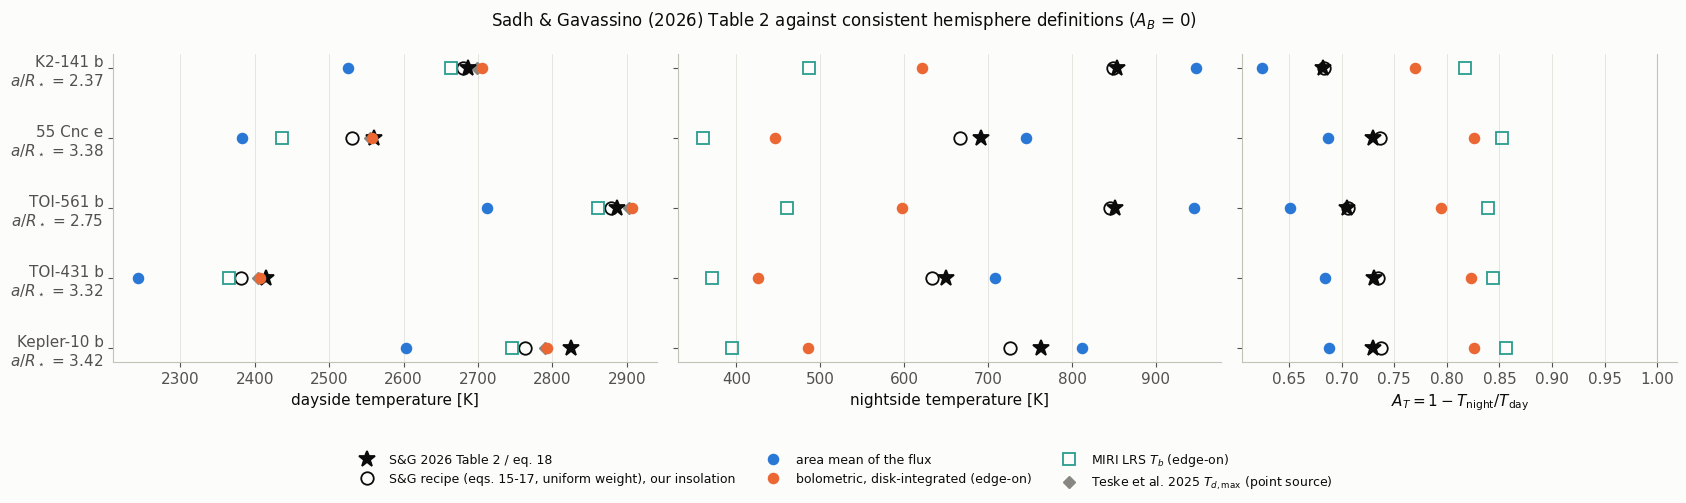

In [9]:
fig = plot_sg_comparison(sg, band_label=instrument_label(SURVEY_BAND, oneline=True))
plt.show()